# Кластеризация k-средних

In [6]:
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans

# функция, которая позволяет получить воспроизводимые результаты при использовании генератора случайных чисел.
np.random.seed(5)

In [7]:
import pandas as pd

In [8]:
data = pd.read_csv("diamonds.csv")
data

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...,...
53935,53936,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,53937,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,53938,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,53939,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [9]:
data_reduced = data.sample(n=2000, random_state=42)
data_reduced.drop(columns=[data_reduced.columns[0]], inplace=True)
data_reduced

,carat,cut,color,clarity,depth,table,price,x,y,z
1388,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
50052,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
41645,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
42377,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
17244,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61
...,...,...,...,...,...,...,...,...,...,...
48985,0.23,Ideal,F,VVS2,61.4,57.0,538,3.96,3.99,2.44
44876,0.52,Ideal,G,VS1,62.3,54.0,1629,5.15,5.18,3.22
27789,0.37,Premium,E,SI1,59.3,58.0,649,4.73,4.75,2.81
51231,0.56,Ideal,E,VS1,60.0,55.0,2352,5.43,5.40,3.25


In [31]:
# Кластеризация k-средних

In [11]:
from sklearn.preprocessing import StandardScaler

In [12]:
from sklearn.preprocessing import LabelEncoder

data_encoded = data_reduced.copy()

label_encoders = {}
for column in data_encoded.columns:
    if data_encoded[column].dtype == 'object':
        le = LabelEncoder()
        data_encoded[column] = le.fit_transform(data_encoded[column])
        label_encoders[column] = le
        
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data_encoded)

In [17]:
pip install yellowbrick

Note: you may need to restart the kernel to use updated packages.


In [18]:
from yellowbrick.cluster import KElbowVisualizer

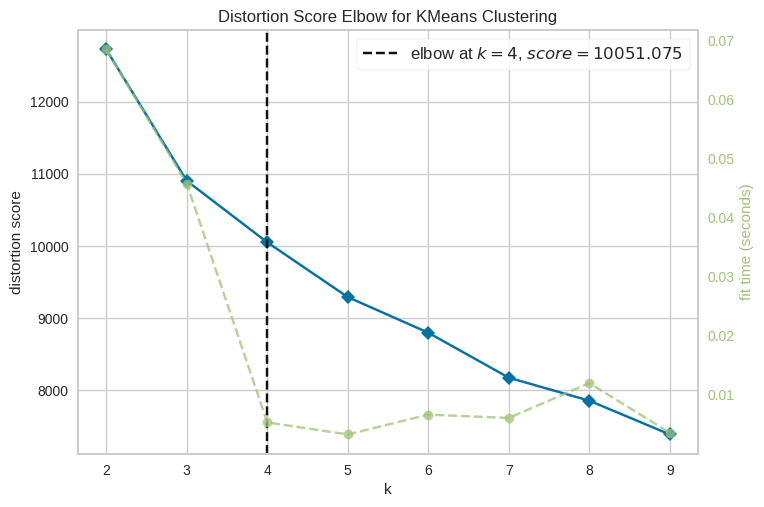

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [19]:
# определение оптимального числа кластеров
model = KMeans()
# создается объект `KElbowVisualizer`, который позволяет нам определить оптимальное количество кластеров. 
# Параметр `k` указывает диапазон числа кластеров, который мы хотим исследовать.
visualizer = KElbowVisualizer(model, k=(2,10)) # https://www.scikit-yb.org/en/latest/api/cluster/elbow.html
# Метод `fit()` принимает набор данных `X_scaled` и подгоняет модель к этим данным.
visualizer.fit(X_scaled)
visualizer.show()

In [20]:
# оптимальное число кластеров выбрано как 4
md = KMeans(n_clusters=4, n_init="auto")
# https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
md.fit(X_scaled)
labels = md.labels_

In [21]:
import pandas as pd

clst_res = pd.DataFrame( data = X_scaled , columns= data_encoded.columns)
# Добавление столбца `"clusters"` к DataFrame `clst_res` и заполнение
# его значениями меток кластеров `labels`, полученных после кластеризации.
clst_res["clusters"] = labels
clst_res

,carat,cut,color,clarity,depth,table,price,x,y,z,clusters
0,-1.142526,-0.512506,0.243853,1.226034,0.227234,-0.598855,-0.826309,-1.522225,-1.503951,-1.505891,2
1,-0.451299,1.438041,-0.346590,1.799484,-1.263060,-0.162213,-0.428120,-0.250225,-0.269530,-0.392165,1
2,-0.817243,-0.512506,-0.937033,1.799484,0.227234,-1.035497,-0.661650,-0.838633,-0.860661,-0.829197,2
3,-0.756252,0.462767,-0.937033,1.799484,-0.695329,-0.162213,-0.645645,-0.700184,-0.730264,-0.786903,1
4,1.520728,-0.512506,-0.937033,-0.494313,0.369167,-1.035497,0.711641,1.480388,1.425626,1.511037,0
...,...,...,...,...,...,...,...,...,...,...,...
1995,-1.162856,-0.512506,-0.346590,1.799484,-0.269530,-0.162213,-0.831402,-1.530878,-1.512644,-1.548184,2
1996,-0.573281,-0.512506,0.243853,0.079136,0.369167,-1.472139,-0.566832,-0.501164,-0.478164,-0.448556,2
1997,-0.878233,0.462767,-0.937033,-1.067762,-1.759825,0.274430,-0.804484,-0.864592,-0.851968,-1.026566,1
1998,-0.491960,-0.512506,-0.937033,0.079136,-1.263060,-1.035497,-0.391502,-0.258878,-0.286916,-0.406263,2


In [22]:
clst_res_mn = clst_res.groupby(['clusters'])[data_encoded.columns].mean()

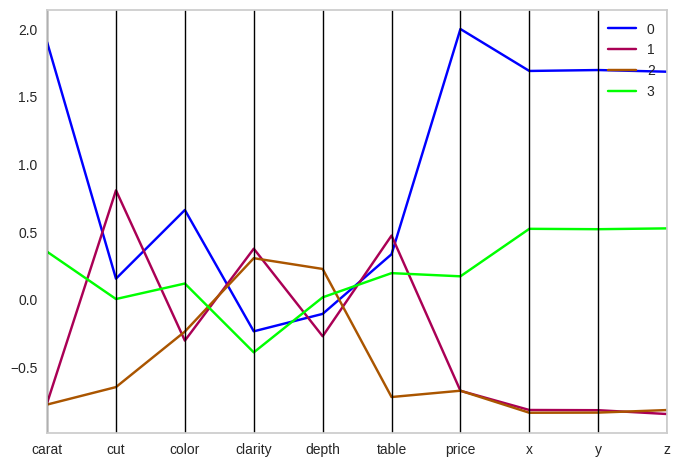

In [23]:
from pandas.plotting import parallel_coordinates
df  = clst_res_mn.reset_index()
parallel_coordinates(df, class_column = 'clusters' , colormap=plt.get_cmap("brg"))
plt.show()

In [32]:
#Иерархическая кластеризация

In [25]:
from scipy.cluster import hierarchy
clusters = hierarchy.linkage(X_scaled, method = "ward")

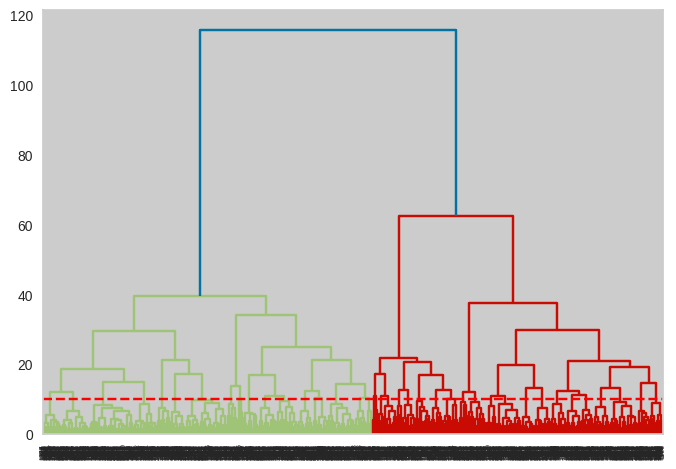

In [26]:
dendrogram = hierarchy.dendrogram(clusters)
# Выделение кластеров
plt.axhline(10, color='red', linestyle='--')

In [27]:
from sklearn.cluster import AgglomerativeClustering

clustering_model = AgglomerativeClustering(n_clusters=4, linkage="ward")
clustering_model.fit(X_scaled)

,n_clusters,4
,metric,'euclidean'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'ward'
,distance_threshold,None
,compute_distances,False


In [28]:
df_clst = pd.DataFrame(data_encoded, columns = data_encoded.columns)
df_clst['clusters'] = clustering_model.labels_

In [33]:
# группировка данных по столбцу кластеры
grouped = df_clst.groupby('clusters')
# Сводная статистика для остальных столбцов
summary = grouped.agg(['mean', 'max', 'min', 'count'])
summary.T

clusters                  0            1             2            3
carat   mean       0.987088     0.431132      1.735125     0.453216
        max        1.550000     1.180000      4.000000     0.960000
        min        0.400000     0.230000      1.000000     0.230000
        count    656.000000   468.000000    279.000000   597.000000
cut     mean       2.640244     3.032051      2.688172     1.926298
        max        4.000000     4.000000      4.000000     4.000000
        min        0.000000     0.000000      0.000000     0.000000
        count    656.000000   468.000000    279.000000   597.000000
color   mean       2.849085     1.997863      3.756272     2.214405
        max        6.000000     6.000000      6.000000     6.000000
        min        0.000000     0.000000      0.000000     0.000000
        count    656.000000   468.000000    279.000000   597.000000
clarity mean       3.304878     4.243590      3.315412     4.430486
        max        7.000000     7.000000      7.000000     7.000000
        min        0.000000     0.000000      0.000000     0.000000
        count    656.000000   468.000000    279.000000   597.000000
depth   mean      62.094512    61.292308     61.511828    61.941374
        max       69.300000    64.400000     68.300000    67.000000
        min       57.800000    55.300000     55.200000    58.900000
        count    656.000000   468.000000    279.000000   597.000000
table   mean      57.466463    58.632265     58.376344    55.809213
        max       64.000000    73.000000     69.000000    61.000000
        min       52.000000    52.000000     53.000000    49.000000
        count    656.000000   468.000000    279.000000   597.000000
price   mean    4854.859756  1219.138889  12007.379928  1386.013400
        max    13168.000000  6841.000000  18803.000000  6607.000000
        min      735.000000   360.000000   3342.000000   373.000000
        count    656.000000   468.000000    279.000000   597.000000
x       mean       6.341601     4.795107      7.678280     4.877571
        max        7.470000     6.830000     10.010000     6.280000
        min        4.620000     3.880000      6.490000     3.900000
        count    656.000000   468.000000    279.000000   597.000000
y       mean       6.333628     4.798825      7.677312     4.886801
        max        7.380000     6.880000      9.940000     6.240000
        min        4.500000     3.930000      6.560000     3.940000
        count    656.000000   468.000000    279.000000   597.000000
z       mean       3.932622     2.936902      4.722258     3.022730
        max        4.590000     4.090000      6.310000     3.920000
        min        2.980000     2.360000      3.780000     2.410000
        count    656.000000   468.000000    279.000000   597.000000